<a href="https://colab.research.google.com/github/Noadori34/Web-analytics-project/blob/main/Final_data_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup
from google.colab import userdata

API_KEY = userdata.get('API_KEY')  # <-- Paste your key inside the quotes
BASE_URL = "https://himalayas.app/jobs/api/search"

HEADERS = {
    "User-Agent": "UniversityResearchProject/1.0",
    "Authorization": f"Bearer {API_KEY}",
}

SEARCH_QUERIES = [
    "data scientist",
    "machine learning",
    "data engineer",
    "data analyst",
    "artificial intelligence",
    "applied scientist",
]

jobs_by_guid = {}

for query in SEARCH_QUERIES:
    print(f"Searching for: '{query}'...")
    page = 1

    while True:
        params = {
            "q": query,
            "country": "US",       # Remove or change if you want global listings
            "sort": "recent",
            "page": page,
        }

        resp = requests.get(BASE_URL, params=params, headers=HEADERS, timeout=15)
        if resp.status_code == 429:
            print("Rate limited — pausing 10 seconds...")
            time.sleep(10)
            continue
        resp.raise_for_status()

        jobs = resp.json().get("jobs", [])
        if not jobs:
            break  # No more pages for this query

        for job in jobs:
            guid = job.get("guid")
            if guid and guid not in jobs_by_guid:
                # Convert HTML description to clean plain text
                raw_html = job.get("description", "")
                clean_text = BeautifulSoup(raw_html, "html.parser").get_text(separator=" ", strip=True)
                job["clean_description"] = " ".join(clean_text.split())
                jobs_by_guid[guid] = job

        page += 1
        time.sleep(1)  # Polite 1-second delay between pages

df = pd.DataFrame(jobs_by_guid.values())

# Inspect the unique categories returned so you can refine further if needed
print("Top parent categories:", df["parentCategories"].explode().value_counts().head(10))

# Filter to keep only jobs with explicit salary figures
df_with_salary = df[df["minSalary"].notna() | df["maxSalary"].notna()].copy()

# Save to CSV
cols = [
    "guid", "title", "companyName", "seniority", "employmentType",
    "categories", "parentCategories", "minSalary", "maxSalary",
    "salaryPeriod", "currency", "clean_description"
]
df_with_salary[cols].to_csv("himalayas_data_science_jobs.csv", index=False)
print(f"Saved {len(df_with_salary)} unique Data Science jobs with salary data.")

Searching for: 'data scientist'...
Searching for: 'machine learning'...
Searching for: 'data engineer'...
Searching for: 'data analyst'...
Searching for: 'artificial intelligence'...
Searching for: 'applied scientist'...
Top parent categories: parentCategories
Data Science         3045
Developer            2871
Sales                 539
Operations            487
Finance               372
Product               291
Marketing             289
Hardware Engineer     221
Customer Service      190
Healthcare            147
Name: count, dtype: int64
Saved 4538 unique Data Science jobs with salary data.


In [16]:
df_with_salary.iloc[0]

,0
title,Principal Data Analyst
excerpt,Our mission at HubSpot is to help millions of ...
companyName,HubSpot
companySlug,hubspot
companyLogo,https://cdn-images.himalayas.app/pgeb5qfnlbpwv...
employmentType,Full Time
minSalary,152200.0
maxSalary,243500.0
salaryPeriod,annual
seniority,[Senior]


In [17]:
import re

SKILL_PATTERNS = {
    # Programming Languages
    "Python": r"\bpython\b",
    "SQL": r"\bsql\b",
    "R": r"\b[Rr]\b",  # Matches standalone 'R' or 'r'
    "C++": r"\bc\+\+|\bcpp\b",
    "C#": r"\bc\#|\bc-sharp\b",
    "Java": r"\bjava\b",
    "JavaScript": r"\bjavascript\b|\bjs\b",
    "TypeScript": r"\btypescript\b|\bts\b",
    "Go": r"\bgolang\b|\bgo\b",
    "Rust": r"\brust\b",
    "Scala": r"\bscala\b",
    "Bash/Shell": r"\bbash\b|\bshell\b",

    # AI, ML & Data Science
    "PyTorch": r"\bpytarch\b|\bpytorch\b",
    "TensorFlow": r"\btensorflow\b|\btf\b",
    "Keras": r"\bkeras\b",
    "Scikit-Learn": r"\bscikit-learn\b|\bsklearn\b",
    "Pandas": r"\bpandas\b",
    "NumPy": r"\bnumpy\b",
    "Apache Spark": r"\bspark\b|\bpyspark\b",
    "Hadoop": r"\bhadoop\b",
    "Airflow": r"\bairflow\b",
    "Databricks": r"\bdatabricks\b",
    "LangChain": r"\blangchain\b",
    "Hugging Face": r"\bhugging\s*face\b",
    "LLM / GenAI": r"\bllm\b|\bllms\b|\bgenai\b|\bgenerative ai\b|\btransformers\b",
    "Computer Vision": r"\bcomputer vision\b|\bopencv\b",
    "NLP": r"\bnlp\b|\bnatural language processing\b",

    # Cloud & DevOps
    "AWS": r"\baws\b|\bamazon web services\b",
    "Azure": r"\bazure\b",
    "GCP": r"\bgcp\b|\bgoogle cloud\b",
    "Docker": r"\bdocker\b",
    "Kubernetes": r"\bkubernetes\b|\bk8s\b",
    "Terraform": r"\bterraform\b",
    "Linux": r"\blinux\b|\bunix\b",
    "Git": r"\bgit\b|\bgithub\b|\bgitlab\b",
    "CI/CD": r"\bci\/cd\b|\bcontinuous integration\b",

    # Databases & Storage
    "PostgreSQL": r"\bpostgres\b|\bpostgresql\b",
    "MySQL": r"\bmysql\b",
    "MongoDB": r"\bmongodb\b|\bmongo\b",
    "Redis": r"\bredis\b",
    "Snowflake": r"\bsnowflake\b",
    "BigQuery": r"\bbigquery\b",
    "Redshift": r"\bredshift\b",

    # BI & Visualization
    "Tableau": r"\btableau\b",
    "Power BI": r"\bpower bi\b|\bpowerbi\b",
    "Looker": r"\blooker\b"
}

def extract_skills(description):
    """Scans job description text and returns a list of matched skills."""
    if not isinstance(description, str) or not description:
        return []

    found_skills = []
    text_lower = description.lower()

    for skill_name, pattern in SKILL_PATTERNS.items():
        if re.search(pattern, text_lower, re.IGNORECASE):
            found_skills.append(skill_name)

    return found_skills

# 2. Extract skills as a list column
df_with_salary['skills_list'] = df_with_salary['clean_description'].apply(extract_skills)

# 3. Create a comma-separated string column for easy display/CSV export
df_with_salary['skills'] = df_with_salary['skills_list'].apply(lambda x: ", ".join(x) if x else "None Specified")

# 4. View a sample of the results
df_with_salary

,title,excerpt,companyName,companySlug,companyLogo,employmentType,minSalary,maxSalary,salaryPeriod,seniority,...,categories,parentCategories,description,pubDate,expiryDate,applicationLink,guid,clean_description,skills_list,skills
0,Principal Data Analyst,Our mission at HubSpot is to help millions of ...,HubSpot,hubspot,https://cdn-images.himalayas.app/pgeb5qfnlbpwv...,Full Time,152200.00,243500.00,annual,[Senior],...,"[Principal-Data-Analyst, Measurement-Analyst, ...",[],"<p>Our mission at <a href=""https://himalayas.a...",1794475185,1799659185,https://himalayas.app/companies/hubspot/jobs/p...,https://himalayas.app/companies/hubspot/jobs/p...,Our mission at HubSpot is to help millions of ...,"[Go, LLM / GenAI]","Go, LLM / GenAI"
1,Competitive Data Scientist (Kaggle) – Remote (...,"IMPORTANT: after you apply, please check your ...",RemoteJobsOne,remotejobsone,https://cdn-images.himalayas.app/7fzya4qky644j...,Contractor,60.00,120.00,hourly,[Mid-level],...,"[Data-Scientist, Machine-Learning-Engineer, Qu...",[Data Science],"<p><strong>IMPORTANT: after you apply, please ...",1794472799,1799656799,https://himalayas.app/companies/remotejobsone/...,https://himalayas.app/companies/remotejobsone/...,"IMPORTANT: after you apply, please check your ...",[Python],Python
2,"Senior Scientist, Computational Pathology and ...",Career CategoryResearchJob DescriptionAt Amgen...,Amgen,amgen,https://cdn-images.himalayas.app/ygg1esm3yk1c2...,Full Time,133673.55,180852.45,annual,[Senior],...,"[Senior-Scientist, Computational-Pathologist, ...","[Research & Development, Data Science]",<h3><b>Career Category</b></h3>Research<h3><b>...,1794466407,1799650406,https://himalayas.app/companies/amgen/jobs/sen...,https://himalayas.app/companies/amgen/jobs/sen...,Career Category Research Job Description At Am...,"[Python, R, Scikit-Learn, NumPy, Computer Visi...","Python, R, Scikit-Learn, NumPy, Computer Visio..."
3,Data Scientist | Modeling,Machinify is a leading healthcare intelligence...,Machinify,machinify,https://cdn-images.himalayas.app/b9v484aojf6w5...,Full Time,180000.00,230000.00,annual,[Senior],...,"[Data-Scientist, Machine-Learning-Scientist, H...",[Data Science],"<div class=""content-intro""><p><a href=""https:/...",1794465580,1799649579,https://himalayas.app/companies/machinify/jobs...,https://himalayas.app/companies/machinify/jobs...,Machinify is a leading healthcare intelligence...,"[Python, SQL, R]","Python, SQL, R"
4,"Senior Data Scientist, Applied AI and Agentic ...",Model complex business problems and discoverin...,VSP Vision,vsp-vision,https://cdn-images.himalayas.app/qdbcj6l66q45f...,Full Time,84000.00,141750.00,annual,[Senior],...,"[Data-Scientist, Applied-AI-Engineer, AI-Solut...",[Data Science],Model complex business problems and discoverin...,1794455665,1799639664,https://himalayas.app/companies/vsp-vision/job...,https://himalayas.app/companies/vsp-vision/job...,Model complex business problems and discoverin...,"[Python, JavaScript, TypeScript, LLM / GenAI, ...","Python, JavaScript, TypeScript, LLM / GenAI, S..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7957,Lead Biostatistician (IVD Analytical),This is an exciting opportunity to advance Nat...,Natera,natera,https://cdn-images.himalayas.app/1e5nqzbnkuslv...,Full Time,130900.00,163600.00,annual,[Senior],...,"[Lead-Biostatistician, Biostatistician, Statis...",[Research & Development],<p>This is an exciting opportunity to advance ...,1794459066,1799643065,https://himalayas.app/companies/natera/jobs/le...,https://himalayas.app/companies/natera/jobs/le...,This is an exciting opportunity to advance Nat...,[R],R
7959,Principal Biology Specialist,About TaskUs:TaskUs is a provider of outsource...,TaskUs,taskus,https://cdn-images.himalayas.app/jtyt8ntn3ts50...,Full Time,150000.00,220000.00,annual,[Senior],...,"[Biology-Specialist, Biosecurity-Analyst, Biol...",[],"<h3>About <a href=""https://himalayas.app/compa...",1793256956,1798440955,https://himala

In [46]:
df_with_salary_relevant = df_with_salary[df_with_salary['skills'] != 'None Specified']

In [47]:
df_with_salary_relevant.reset_index(drop=True)

,title,excerpt,companyName,companySlug,companyLogo,employmentType,minSalary,maxSalary,salaryPeriod,seniority,...,categories,parentCategories,description,pubDate,expiryDate,applicationLink,guid,clean_description,skills_list,skills
0,Principal Data Analyst,Our mission at HubSpot is to help millions of ...,HubSpot,hubspot,https://cdn-images.himalayas.app/pgeb5qfnlbpwv...,Full Time,152200.00,243500.00,annual,[Senior],...,"[Principal-Data-Analyst, Measurement-Analyst, ...",[],"<p>Our mission at <a href=""https://himalayas.a...",1794475185,1799659185,https://himalayas.app/companies/hubspot/jobs/p...,https://himalayas.app/companies/hubspot/jobs/p...,Our mission at HubSpot is to help millions of ...,"[Go, LLM / GenAI]","Go, LLM / GenAI"
1,Competitive Data Scientist (Kaggle) – Remote (...,"IMPORTANT: after you apply, please check your ...",RemoteJobsOne,remotejobsone,https://cdn-images.himalayas.app/7fzya4qky644j...,Contractor,60.00,120.00,hourly,[Mid-level],...,"[Data-Scientist, Machine-Learning-Engineer, Qu...",[Data Science],"<p><strong>IMPORTANT: after you apply, please ...",1794472799,1799656799,https://himalayas.app/companies/remotejobsone/...,https://himalayas.app/companies/remotejobsone/...,"IMPORTANT: after you apply, please check your ...",[Python],Python
2,"Senior Scientist, Computational Pathology and ...",Career CategoryResearchJob DescriptionAt Amgen...,Amgen,amgen,https://cdn-images.himalayas.app/ygg1esm3yk1c2...,Full Time,133673.55,180852.45,annual,[Senior],...,"[Senior-Scientist, Computational-Pathologist, ...","[Research & Development, Data Science]",<h3><b>Career Category</b></h3>Research<h3><b>...,1794466407,1799650406,https://himalayas.app/companies/amgen/jobs/sen...,https://himalayas.app/companies/amgen/jobs/sen...,Career Category Research Job Description At Am...,"[Python, R, Scikit-Learn, NumPy, Computer Visi...","Python, R, Scikit-Learn, NumPy, Computer Visio..."
3,Data Scientist | Modeling,Machinify is a leading healthcare intelligence...,Machinify,machinify,https://cdn-images.himalayas.app/b9v484aojf6w5...,Full Time,180000.00,230000.00,annual,[Senior],...,"[Data-Scientist, Machine-Learning-Scientist, H...",[Data Science],"<div class=""content-intro""><p><a href=""https:/...",1794465580,1799649579,https://himalayas.app/companies/machinify/jobs...,https://himalayas.app/companies/machinify/jobs...,Machinify is a leading healthcare intelligence...,"[Python, SQL, R]","Python, SQL, R"
4,"Senior Data Scientist, Applied AI and Agentic ...",Model complex business problems and discoverin...,VSP Vision,vsp-vision,https://cdn-images.himalayas.app/qdbcj6l66q45f...,Full Time,84000.00,141750.00,annual,[Senior],...,"[Data-Scientist, Applied-AI-Engineer, AI-Solut...",[Data Science],Model complex business problems and discoverin...,1794455665,1799639664,https://himalayas.app/companies/vsp-vision/job...,https://himalayas.app/companies/vsp-vision/job...,Model complex business problems and discoverin...,"[Python, JavaScript, TypeScript, LLM / GenAI, ...","Python, JavaScript, TypeScript, LLM / GenAI, S..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3547,AI Software Engineer,Job DescriptionNetImpact Strategies is seeking...,NetImpact Strategies,netimpact-strategies,https://cdn-images.himalayas.app/8erpushw8io5e...,Full Time,107000.00,140000.00,annual,[Mid-level],...,"[Fullstack-Development, Software-Engineer, Bac...","[Developer, Data Science]","<h3>Job Description</h3><p><a href=""https://hi...",1792611123,1795140283,https://himalayas.app/companies/netimpact-stra...,https://himalayas.app/companies/netimpact-stra...,Job Description NetImpact Strategies is seekin...,"[SQL, C#, Java, AWS, Azure, Docker, Kubernetes...","SQL, C#, Java, AWS, Azure, Docker, Kubernetes,..."
3548,AI Product Manager,Position Summary The AI Product Manager serves...,St. Jude Children's Research Hospital,st-jude-children-s-research-hospital,https://cdn-images.himalayas.app/s2x0va4w9xkte...,Full Time,94640.00,169520

In [48]:
print("Currencies:\n", df_with_salary_relevant["currency"].value_counts(dropna=False))
print("\nSalary Periods:\n", df_with_salary_relevant["salaryPeriod"].value_counts(dropna=False))

Currencies:
 currency
USD    3518
CAD      23
INR       6
EUR       3
GBP       2
Name: count, dtype: int64

Salary Periods:
 salaryPeriod
annual     3494
hourly       41
monthly      16
weekly        1
Name: count, dtype: int64


In [49]:
import numpy as np
import pandas as pd

# 1. Make an explicit, cleanly indexed copy before modifying columns
df_with_salary_relevant = df_with_salary_relevant.reset_index(drop=True)

# 2. Ensure salary columns are numeric
df_with_salary_relevant["minSalary"] = pd.to_numeric(df_with_salary_relevant["minSalary"], errors="coerce")
df_with_salary_relevant["maxSalary"] = pd.to_numeric(df_with_salary_relevant["maxSalary"], errors="coerce")

# 3. Calculate midpoint
df_with_salary_relevant["midpoint_salary"] = df_with_salary_relevant[["minSalary", "maxSalary"]].mean(axis=1)

# 4. Map salaryPeriod to annual multipliers
period_clean = df_with_salary_relevant["salaryPeriod"].fillna("unknown").str.lower().str.strip()

multipliers = {
    "annual": 1,
    "yearly": 1,
    "year": 1,
    "monthly": 12,
    "month": 12,
    "weekly": 52,
    "week": 52,
    "daily": 260,
    "day": 260,
    "hourly": 2080,
    "hour": 2080,
}

df_with_salary_relevant["multiplier"] = period_clean.map(multipliers)

# Fallback when salaryPeriod is missing
df_with_salary_relevant.loc[
    df_with_salary_relevant["multiplier"].isna() & (df_with_salary_relevant["midpoint_salary"] < 500),
    "multiplier",
] = 2080
df_with_salary_relevant.loc[
    df_with_salary_relevant["multiplier"].isna() & (df_with_salary_relevant["midpoint_salary"] >= 15000),
    "multiplier",
] = 1

# 5. Compute annualized salary
df_with_salary_relevant["annual_salary"] = (
    df_with_salary_relevant["midpoint_salary"] * df_with_salary_relevant["multiplier"])

In [50]:
df_with_salary_relevant = df_with_salary_relevant[~df_with_salary_relevant['employmentType'].isin(['Contractor', 'Part Time', 'Temporary'])].reset_index()

In [51]:
df_with_salary_relevant['employmentType'].value_counts()

,count
employmentType,
Full Time,3442
Other,37
Intern,23


In [52]:
df_with_salary_relevant.iloc[0]

,0
index,0
title,Principal Data Analyst
excerpt,Our mission at HubSpot is to help millions of ...
companyName,HubSpot
companySlug,hubspot
companyLogo,https://cdn-images.himalayas.app/pgeb5qfnlbpwv...
employmentType,Full Time
minSalary,152200.0
maxSalary,243500.0
salaryPeriod,annual


In [54]:
df_with_salary_relevant = df_with_salary_relevant.drop(columns=['excerpt', 'companyLogo', 'description', 'applicationLink', 'guid', 'multiplier'])

In [58]:
df_with_salary_relevant = df_with_salary_relevant[df_with_salary_relevant['currency'] == 'USD'].reset_index()

In [60]:
df_with_salary_relevant.to_csv('web_analytics_dataset.csv', index=False)

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [10]:
import pandas as pd
import ast
from itertools import combinations

In [4]:
df_with_salary_relevant = pd.read_csv('/content/drive/MyDrive/web_analytics_dataset.csv')

In [8]:
df_with_salary_relevant.iloc[0]['skills_list']

"['Go', 'LLM / GenAI']"

In [11]:
SKILL_COL = "skills_list"

def to_skill_list(val):
    if isinstance(val, list):
        return sorted(set(s.strip() for s in val if s and s != "NONE_LISTED"))
    if isinstance(val, str):
        val = val.strip()
        if not val or val == "NONE_LISTED":
            return []
        if val.startswith("["):
            parsed = ast.literal_eval(val)
            return sorted(set(s.strip() for s in parsed if s))
        return sorted(set(s.strip() for s in val.split(",") if s.strip()))
    return []

df = df_with_salary_relevant.copy()
df["skills_list"] = df[SKILL_COL].apply(to_skill_list)

In [13]:
exploded = df.explode("skills_list").dropna(subset=["skills_list"])

skill_stats = (
    exploded.groupby("skills_list")["annual_salary"]
    .agg(
        job_count="count",
        median_salary="median",
        mean_salary="mean",
        std_salary="std",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
    .rename(columns={"skills_list": "skill"})
)

skill_stats["pct_of_jobs"] = (skill_stats["job_count"] / len(df) * 100).round(1)
skill_stats = skill_stats.sort_values("job_count", ascending=False)

print("Top 20 Most Frequent Skills:")
print(skill_stats.head(20).to_string(index=False))

# Optional: View highest-median-salary skills among those appearing in at least 15 jobs
print("\nTop 15 Highest-Paying Skills (min 15 postings):")
print(
    skill_stats[skill_stats["job_count"] >= 15]
    .sort_values("median_salary", ascending=False)
    .head(15)
    .to_string(index=False))

Top 20 Most Frequent Skills:
       skill  job_count  median_salary   mean_salary   std_salary        q25        q75  pct_of_jobs
      Python       1789    168100.0000 175395.813913 77532.871112 131400.000 201200.000         51.6
         SQL       1461    144750.0000 150671.692211 56109.338237 114500.000 175500.000         42.1
 LLM / GenAI       1014    183575.0000 191891.185947 79534.634065 150000.000 217500.000         29.2
         AWS        888    170000.0000 176689.856402 61765.819144 140000.000 200000.000         25.6
          Go        837    168180.0000 171839.037873 63845.018026 125900.000 204000.000         24.1
       Azure        654    160000.0000 167185.312209 53532.368444 130000.000 194100.000         18.9
       CI/CD        565    160500.0000 167117.739611 49680.922092 135000.000 195000.000         16.3
         GCP        550    170000.0000 175900.986745 53587.209102 145000.000 200000.000         15.9
           R        483    150920.0000 158247.192277 56801.472

In [14]:
def get_combo_stats(dataframe, k=2, min_count=5):
    combo_salaries = {}
    for _, row in dataframe.iterrows():
        skills = row["skills_list"]
        sal = row["annual_salary"]
        if len(skills) >= k:
            for combo in combinations(skills, k):
                combo_salaries.setdefault(combo, []).append(sal)

    rows = []
    for combo, sals in combo_salaries.items():
        if len(sals) >= min_count:
            s = pd.Series(sals)
            rows.append({
                "combination": " + ".join(combo),
                "job_count": len(sals),
                "pct_of_jobs": round(len(sals) / len(dataframe) * 100, 1),
                "median_salary": s.median(),
                "mean_salary": s.mean(),
            })

    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values("job_count", ascending=False)

top_pairs = get_combo_stats(df, k=2, min_count=5)
top_triplets = get_combo_stats(df, k=3, min_count=5)

print("Top 15 Most Common Skill Pairs:")
print(top_pairs.head(15).to_string(index=False))

print("\nTop 15 Most Common Skill Triplets:")
print(top_triplets.head(15).to_string(index=False))

Top 15 Most Common Skill Pairs:
         combination  job_count  pct_of_jobs  median_salary   mean_salary
        Python + SQL        980         28.3      150000.00 158821.025005
LLM / GenAI + Python        604         17.4      182500.00 189052.875786
        AWS + Python        593         17.1      170000.00 174802.801096
         AWS + Azure        461         13.3      170000.00 176851.972451
      Azure + Python        398         11.5      160000.00 167874.436106
           AWS + GCP        396         11.4      175000.00 180492.782045
           AWS + SQL        396         11.4      154843.25 157612.222753
        GCP + Python        380         11.0      170000.00 175807.153842
         Go + Python        376         10.8      181925.00 187485.875931
      CI/CD + Python        374         10.8      162500.00 167255.348917
          Python + R        360         10.4      150250.00 157889.052292
         Azure + GCP        351         10.1      175000.00 181508.134501
   AWS

In [15]:
df["skill_count"] = df["skills_list"].apply(len)

# 1. Coverage & distribution of skills per job
zero_skill_jobs = (df["skill_count"] == 0).sum()
print(f"Jobs with 0 extracted skills: {zero_skill_jobs} / {len(df)} ({zero_skill_jobs / len(df) * 100:.1f}%)")
print("\nDistribution of Number of Skills per Job:")
print(df["skill_count"].describe())

# 2. Correlation between number of skills listed and salary
pearson_r = df["skill_count"].corr(df["annual_salary"], method="pearson")
spearman_r = df["skill_count"].corr(df["annual_salary"], method="spearman")
print(f"\nSkill Count vs. Annual Salary -> Pearson r: {pearson_r:.3f} | Spearman rho: {spearman_r:.3f}")

# 3. Breakdown by Seniority (if the column is still in your DataFrame)
if "seniority" in df.columns:
    seniority_stats = (
        df.groupby("seniority", dropna=False)
        .agg(
            job_count=("annual_salary", "count"),
            median_salary=("annual_salary", "median"),
            mean_salary=("annual_salary", "mean"),
            median_skills=("skill_count", "median"),
        )
        .sort_values("median_salary", ascending=False)
    )
    print("\nSalary & Skill Breadth by Seniority:")
    print(seniority_stats)

# Export summary tables to CSVs if you want to build charts or tables in Excel/LaTeX
skill_stats.to_csv("/content/drive/MyDrive/skill_frequency_stats.csv", index=False)
top_pairs.to_csv("/content/drive/MyDrive/skill_pair_stats.csv", index=False)

Jobs with 0 extracted skills: 0 / 3469 (0.0%)

Distribution of Number of Skills per Job:
count    3469.000000
mean        4.407899
std         3.226361
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max        24.000000
Name: skill_count, dtype: float64

Skill Count vs. Annual Salary -> Pearson r: 0.062 | Spearman rho: 0.129

Salary & Skill Breadth by Seniority:
                              job_count  median_salary    mean_salary  \
seniority                                                               
['Executive', 'Senior']               1       300000.0  300000.000000   
['Executive']                        32       250000.0  252764.843750   
['Manager', 'Director']               3       235000.0  237323.333333   
['Director']                        148       215000.0  219568.378378   
['Director', 'Executive']            18       202750.0  218313.888889   
['Senior', 'Executive']               4       200000.0  196506.250000   
['Senior', 'Di

In [16]:
from itertools import combinations
import networkx as nx
import numpy as np
import pandas as pd

MIN_SKILL_JOBS = 10  # Adjust based on your final dataset size

# 1. Count individual skill frequencies and descriptive median salaries
exploded = df.explode("skills_list").dropna(subset=["skills_list"])
skill_summary = (
    exploded.groupby("skills_list")["annual_salary"]
    .agg(count="count", median_salary="median")
)
valid_skills = set(skill_summary[skill_summary["count"] >= MIN_SKILL_JOBS].index)

# 2. Build the undirected weighted graph
G = nx.Graph()

for skill in valid_skills:
    G.add_node(
        skill,
        count=int(skill_summary.loc[skill, "count"]),
        median_salary=float(skill_summary.loc[skill, "median_salary"]),
    )

for skills in df["skills_list"]:
    filtered = [s for s in skills if s in valid_skills]
    for u, v in combinations(filtered, 2):
        if G.has_edge(u, v):
            G[u][v]["weight"] += 1
        else:
            G.add_edge(u, v, weight=1)

# 3. Add Jaccard similarity and inverse distance (for shortest-path metrics)
for u, v, data in G.edges(data=True):
    w = data["weight"]
    union_size = G.nodes[u]["count"] + G.nodes[v]["count"] - w
    data["jaccard"] = w / union_size
    data["distance"] = 1.0 / w  # Stronger co-occurrence = shorter path

print(f"Graph built: {G.number_of_nodes()} skill nodes and {G.number_of_edges()} co-occurrence edges.")

Graph built: 46 skill nodes and 990 co-occurrence edges.


In [17]:
weighted_deg = dict(G.degree(weight="weight"))
betweenness = nx.betweenness_centrality(G, weight="distance", normalized=True)
eigenvector = nx.eigenvector_centrality(G, weight="weight", max_iter=1000)

centrality_df = pd.DataFrame({
    "skill": list(G.nodes()),
    "job_count": [G.nodes[n]["count"] for n in G.nodes()],
    "median_salary": [G.nodes[n]["median_salary"] for n in G.nodes()],
    "weighted_degree": [weighted_deg[n] for n in G.nodes()],
    "betweenness": [round(betweenness[n], 4) for n in G.nodes()],
    "eigenvector": [round(eigenvector[n], 4) for n in G.nodes()],
}).sort_values("weighted_degree", ascending=False)

print("Top 15 Core Skills (by Weighted Degree):")
print(centrality_df.head(15).to_string(index=False))

print("\nTop 10 Bridge Skills (by Betweenness Centrality):")
print(centrality_df.sort_values("betweenness", ascending=False).head(10).to_string(index=False))

Top 15 Core Skills (by Weighted Degree):
       skill  job_count  median_salary  weighted_degree  betweenness  eigenvector
      Python       1789      168100.00             9097       0.8596       0.4547
         SQL       1461      144750.00             6581       0.2040       0.3722
         AWS        888      170000.00             5754       0.0444       0.3221
 LLM / GenAI       1014      183575.00             4619       0.0889       0.2666
       Azure        654      160000.00             4374       0.0000       0.2575
         GCP        550      170000.00             3818       0.0000       0.2208
       CI/CD        565      160500.00             3734       0.0000       0.2183
          Go        837      168180.00             3133       0.0000       0.1840
         Git        468      150000.00             2965       0.0000       0.1749
Apache Spark        378      174255.00             2668       0.0000       0.1589
  Databricks        401      162698.50             2644  

In [18]:
communities = nx.community.louvain_communities(G, weight="weight", seed=42)
modularity = nx.community.modularity(G, communities, weight="weight")
print(f"Detected {len(communities)} skill communities (Modularity = {modularity:.3f}):\n")

node_to_cluster = {}
for idx, comm in enumerate(sorted(communities, key=len, reverse=True)):
    for skill in comm:
        node_to_cluster[skill] = idx

    # Sort skills inside each cluster by frequency
    ordered_skills = sorted(comm, key=lambda s: G.nodes[s]["count"], reverse=True)
    # Descriptive median salary across postings mentioning at least one skill in this cluster
    cluster_mask = df["skills_list"].apply(lambda lst: any(s in comm for s in lst))
    cluster_med_sal = df.loc[cluster_mask, "annual_salary"].median()

    print(f"Cluster {idx + 1} ({len(comm)} skills | Cluster Median Salary: ${cluster_med_sal:,.0f}):")
    print("  ", ", ".join(ordered_skills), "\n")

Detected 3 skill communities (Modularity = 0.094):

Cluster 1 (22 skills | Cluster Median Salary: $166,375):
   AWS, Go, Azure, CI/CD, GCP, Git, Kubernetes, Java, JavaScript, TypeScript, Docker, Terraform, PostgreSQL, C++, Linux, Bash/Shell, C#, Scala, Rust, MySQL, Redis, MongoDB 

Cluster 2 (13 skills | Cluster Median Salary: $155,000):
   Python, SQL, R, Power BI, Snowflake, Databricks, Tableau, Apache Spark, Airflow, BigQuery, Looker, Redshift, Hadoop 

Cluster 3 (11 skills | Cluster Median Salary: $184,750):
   LLM / GenAI, PyTorch, TensorFlow, NLP, Computer Vision, LangChain, Pandas, Scikit-Learn, Hugging Face, NumPy, Keras 



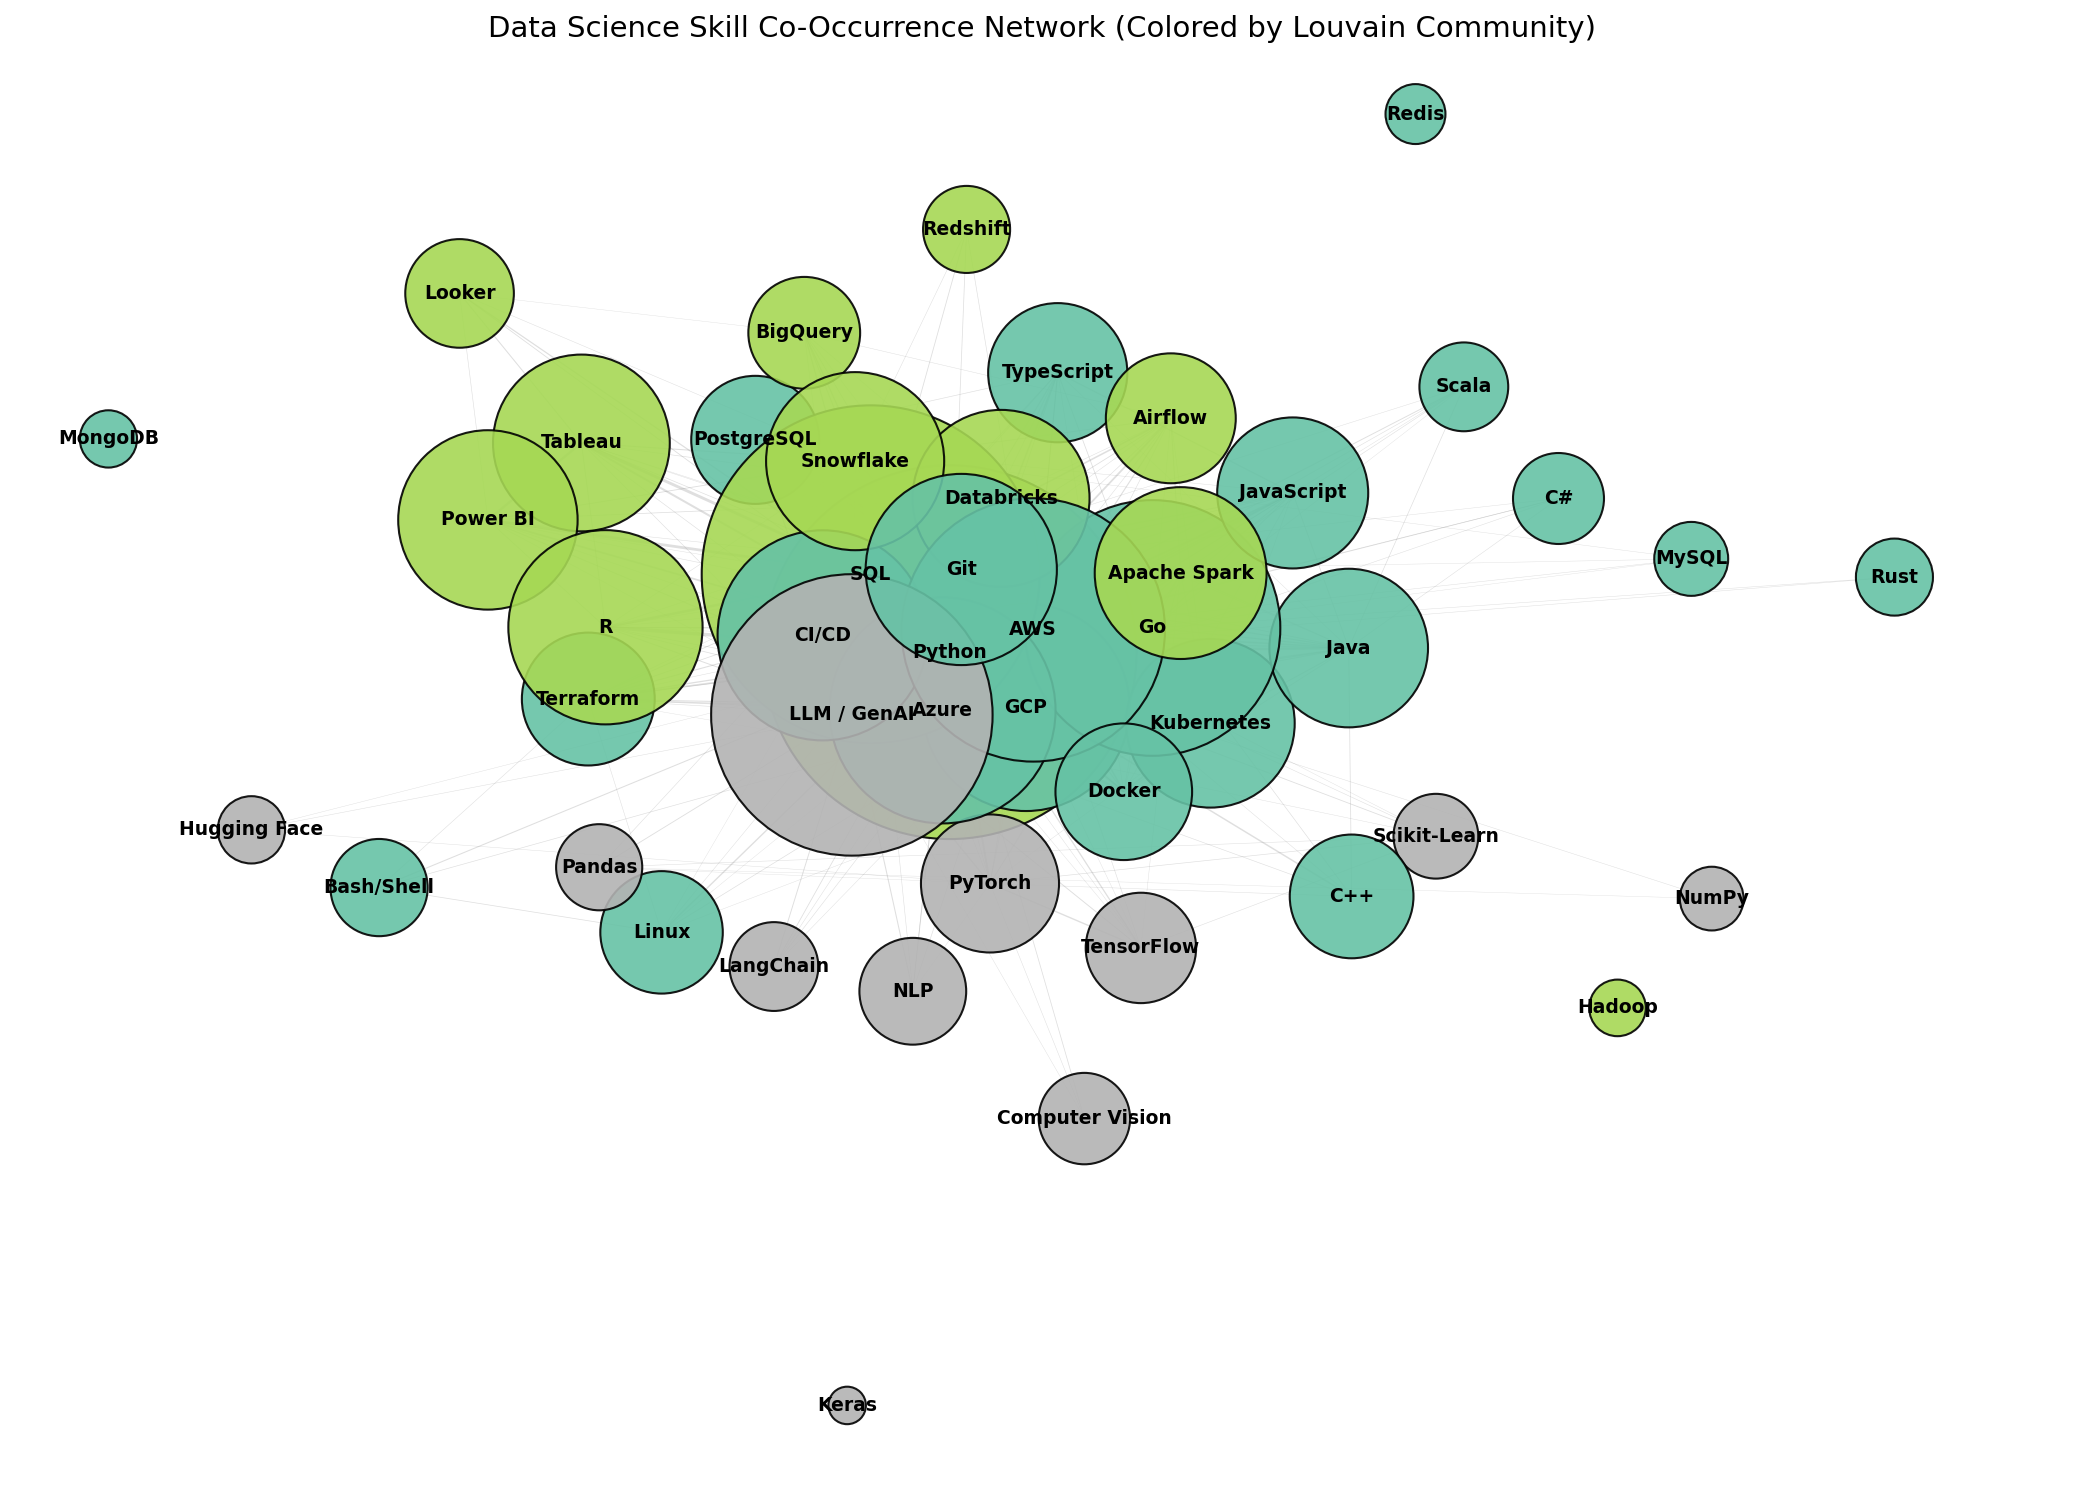

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10), dpi=150)

# Keep only stronger edges for visual clarity
weights = [d["weight"] for _, _, d in G.edges(data=True)]
edge_threshold = np.percentile(weights, 70)  # Show top 30% strongest connections
visible_edges = [(u, v) for u, v, d in G.edges(data=True) if d["weight"] >= edge_threshold]

pos = nx.spring_layout(G, k=0.65, weight="weight", seed=42)

# Node styling: size = job count, color = Louvain community
node_sizes = [G.nodes[n]["count"] * 18 for n in G.nodes()]
node_colors = [node_to_cluster[n] for n in G.nodes()]

# Edge styling: width proportional to co-occurrence count
max_w = max(weights)
edge_widths = [(G[u][v]["weight"] / max_w) * 4.5 for u, v in visible_edges]

nx.draw_networkx_edges(
    G, pos, edgelist=visible_edges, width=edge_widths, alpha=0.25, edge_color="gray"
)
nx.draw_networkx_nodes(
    G, pos, node_size=node_sizes, node_color=node_colors, cmap=plt.cm.Set2, alpha=0.9, edgecolors="black"
)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")

plt.title("Data Science Skill Co-Occurrence Network (Colored by Louvain Community)", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/skill_network.png", dpi=300)
plt.show()

In [20]:
import ast
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import MultiLabelBinarizer

MIN_SKILL_JOBS = 15  # Exclude rare skills to avoid unstable estimates

reg_df = df.copy()

# 1. One-hot encode skills (keeping skills that appear in at least MIN_SKILL_JOBS postings)
mlb = MultiLabelBinarizer()
skill_matrix = pd.DataFrame(
    mlb.fit_transform(reg_df["skills_list"]),
    columns=mlb.classes_,
    index=reg_df.index,
)

frequent_skills = skill_matrix.columns[skill_matrix.sum() >= MIN_SKILL_JOBS]
X_skills = skill_matrix[frequent_skills]

# 2. Clean seniority column into control dummies (handles plain strings or stringified lists)
def parse_seniority(val):
    if pd.isna(val):
        return "Not Specified"
    s = str(val).strip()
    if s.startswith("["):
        parsed = ast.literal_eval(s)
        return parsed[0] if parsed else "Not Specified"
    return s if s else "Not Specified"

if "seniority" in reg_df.columns:
    reg_df["seniority_clean"] = reg_df["seniority"].apply(parse_seniority)
    # Use the most common seniority level as the baseline reference group
    baseline_sen = reg_df["seniority_clean"].mode()[0]
    X_seniority = pd.get_dummies(reg_df["seniority_clean"], prefix="Seniority", dtype=int)
    X_seniority = X_seniority.drop(columns=[f"Seniority_{baseline_sen}"], errors="ignore")
    X = pd.concat([X_skills, X_seniority], axis=1)
    print(f"Controlling for seniority (baseline reference = '{baseline_sen}')")
else:
    X = X_skills.copy()

# 3. Fit OLS on log(annual_salary) with HC3 robust standard errors
y = np.log(reg_df["annual_salary"])
X_const = sm.add_constant(X)

model = sm.OLS(y, X_const).fit(cov_type="HC3")

print(f"Observations: {int(model.nobs)} | R-squared: {model.rsquared:.3f} | Adj. R-squared: {model.rsquared_adj:.3f}\n")

# 4. Build a clean, publication-ready table for the skill coefficients
conf_int = model.conf_int()
results_table = pd.DataFrame({
    "feature": model.params.index,
    "beta": model.params.values,
    "pct_premium": (np.exp(model.params.values) - 1) * 100,
    "std_err": model.bse.values,
    "p_value": model.pvalues.values,
    "ci_low_pct": (np.exp(conf_int[0].values) - 1) * 100,
    "ci_high_pct": (np.exp(conf_int[1].values) - 1) * 100,
})

# Filter to skill rows and attach posting counts
skill_results = results_table[results_table["feature"].isin(frequent_skills)].copy()
skill_results["job_count"] = skill_results["feature"].map(X_skills.sum())
skill_results = skill_results.sort_values("pct_premium", ascending=False)

print("Estimated Conditional Salary Premiums by Skill (Holding Other Skills & Seniority Constant):")
print(
    skill_results[["feature", "job_count", "pct_premium", "p_value", "ci_low_pct", "ci_high_pct"]]
    .round({"pct_premium": 1, "p_value": 4, "ci_low_pct": 1, "ci_high_pct": 1})
    .to_string(index=False)
)

skill_results.to_csv("/content/drive/MyDrive/skill_regression_results.csv", index=False)

Controlling for seniority (baseline reference = 'Senior')
Observations: 3469 | R-squared: 0.371 | Adj. R-squared: 0.361

Estimated Conditional Salary Premiums by Skill (Holding Other Skills & Seniority Constant):
        feature  job_count  pct_premium  p_value  ci_low_pct  ci_high_pct
           Rust         76         18.6   0.0000        11.4         26.3
        PyTorch        244         17.9   0.0000        10.7         25.6
          Scala        101         15.2   0.0001         7.2         23.9
     TypeScript        248         13.9   0.0000         8.3         19.7
            C++        196         13.1   0.0001         6.4         20.1
    LLM / GenAI       1014         10.4   0.0000         7.4         13.4
     Kubernetes        364          9.8   0.0003         4.4         15.5
          Redis         46          9.3   0.0651        -0.6         20.1
         Pandas         95          7.6   0.0724        -0.7         16.6
         Hadoop         41          6.9   0.251

In [21]:
import ast
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import MultiLabelBinarizer

MIN_JOBS_PER_TIER = 35     # Minimum postings required to fit a regression for a seniority tier
MIN_SKILL_IN_TIER = 8      # Minimum postings a skill must appear in within that tier

# 1. Clean seniority labels
def parse_seniority(val):
    if pd.isna(val):
        return "Not Specified"
    s = str(val).strip()
    if s.startswith("["):
        parsed = ast.literal_eval(s)
        return parsed[0] if parsed else "Not Specified"
    return s if s else "Not Specified"

work_df = df.copy()
work_df["seniority_clean"] = work_df["seniority"].apply(parse_seniority)

print("Postings per seniority level:")
print(work_df["seniority_clean"].value_counts(), "\n")

# 2. Fit a separate semi-log OLS model for each qualifying seniority level
stratified_models = {}
stratified_results = []

for tier, sub_df in work_df.groupby("seniority_clean"):
    if len(sub_df) < MIN_JOBS_PER_TIER:
        print(f"Skipping '{tier}' (only {len(sub_df)} jobs — below threshold of {MIN_JOBS_PER_TIER})")
        continue

    mlb = MultiLabelBinarizer()
    skill_mat = pd.DataFrame(
        mlb.fit_transform(sub_df["skills_list"]),
        columns=mlb.classes_,
        index=sub_df.index,
    )

    valid_skills = skill_mat.columns[skill_mat.sum() >= MIN_SKILL_IN_TIER]
    if len(valid_skills) < 2:
        continue

    X = skill_mat[valid_skills]
    y = np.log(sub_df["annual_salary"])
    X_const = sm.add_constant(X)

    model = sm.OLS(y, X_const).fit(cov_type="HC3")
    stratified_models[tier] = model

    pvals = model.pvalues
    pct_prem = (np.exp(model.params) - 1) * 100

    for skill in valid_skills:
        stratified_results.append({
            "seniority": tier,
            "skill": skill,
            "tier_job_count": int(X[skill].sum()),
            "pct_premium": pct_prem[skill],
            "p_value": pvals[skill],
            "sig": "*" if pvals[skill] < 0.05 else "",
        })

strat_df = pd.DataFrame(stratified_results)

# 3. Create a side-by-side comparison table across seniority levels
comparison_pivot = strat_df.pivot(index="skill", columns="seniority", values="pct_premium").round(1)
print("\nEstimated % Salary Premium by Skill & Seniority Level:")
print(comparison_pivot.fillna("—").to_string())

strat_df.to_csv("/content/drive/MyDrive/stratified_skill_premiums.csv", index=False)

Postings per seniority level:
seniority_clean
Senior         2280
Mid-level       737
Director        167
Manager         154
Entry-level      98
Executive        33
Name: count, dtype: int64 

Skipping 'Executive' (only 33 jobs — below threshold of 35)

Estimated % Salary Premium by Skill & Seniority Level:
seniority       Director Entry-level Manager Mid-level  Senior
skill                                                         
AWS                 -3.2       -21.3    11.1       7.9     0.9
Airflow             -0.0           —       —       7.6     3.2
Apache Spark         0.9           —    -9.4       1.1     7.3
Azure               -4.5        21.5    -0.7      10.7    -5.5
Bash/Shell             —           —       —       9.4    -7.7
BigQuery               —           —   -18.5      -0.5     1.9
C#                  74.3           —       —     -14.1    -0.1
C++                    —           —       —       5.4    14.6
CI/CD               -9.3        60.7    -1.4       2.1    -4

In [22]:
def recommend_next_skills(
    known_skills: list[str],
    seniority: str = None,
    top_n: int = 10,
    min_compatibility_pct: float = 5.0,
) -> pd.DataFrame:
    """
    Recommends new skills that maximize expected salary increase given a user's
    current skill set and seniority level.
    """
    # Select seniority-specific model if available; otherwise use pooled model
    if seniority and seniority in stratified_models:
        active_model = stratified_models[seniority]
        model_source = f"Stratified ({seniority})"
        subset_df = work_df[work_df["seniority_clean"] == seniority]
    else:
        active_model = model  # Pooled model from previous step
        model_source = f"Pooled Model (Seniority={seniority or 'Baseline'})"
        subset_df = work_df

    model_features = list(active_model.params.index)
    skill_features = [
        f for f in model_features if f != "const" and not f.startswith("Seniority_")
    ]

    # Case-insensitive matching for user's known skills
    lower_to_canonical = {s.lower(): s for s in skill_features}
    matched_known = []
    for s in known_skills:
        canonical = lower_to_canonical.get(s.lower())
        if canonical:
            matched_known.append(canonical)
    matched_known = sorted(set(matched_known))

    # Helper to predict median annual salary from a feature dictionary
    def predict_salary(skills_active: list[str]) -> float:
        row = pd.DataFrame(0.0, index=[0], columns=model_features)
        if "const" in row.columns:
            row["const"] = 1.0
        for sk in skills_active:
            if sk in row.columns:
                row[sk] = 1.0
        # Set seniority dummy if using pooled model
        if active_model is model and seniority:
            sen_col = f"Seniority_{seniority}"
            if sen_col in row.columns:
                row[sen_col] = 1.0
        log_pred = float(active_model.predict(row).iloc[0])
        return np.exp(log_pred)

    baseline_salary = predict_salary(matched_known)

    # Calculate stack compatibility using real co-occurrence rates
    if matched_known:
        stack_jobs = subset_df[
            subset_df["skills_list"].apply(lambda lst: any(k in lst for k in matched_known))
        ]
    else:
        stack_jobs = subset_df

    recommendations = []
    for candidate in skill_features:
        if candidate in matched_known:
            continue

        new_salary = predict_salary(matched_known + [candidate])
        dollar_gain = new_salary - baseline_salary
        pct_gain = (np.exp(active_model.params[candidate]) - 1) * 100
        pval = active_model.pvalues[candidate]

        # % of jobs requiring user's current stack that ALSO ask for this candidate skill
        if len(stack_jobs) > 0:
            compat = (
                stack_jobs["skills_list"].apply(lambda lst: candidate in lst).mean() * 100
            )
        else:
            compat = 0.0

        if compat >= min_compatibility_pct:
            recommendations.append({
                "recommended_skill": candidate,
                "predicted_new_salary": round(new_salary, 0),
                "expected_dollar_gain": round(dollar_gain, 0),
                "pct_premium": round(pct_gain, 1),
                "stack_compatibility_pct": round(compat, 1),
                "p_value": round(pval, 4),
            })

    rec_df = pd.DataFrame(recommendations).sort_values(
        "expected_dollar_gain", ascending=False
    )

    print(f"Model Used: {model_source}")
    print(f"Recognized Current Skills: {matched_known}")
    print(f"Estimated Baseline Annual Salary: ${baseline_salary:,.0f}\n")
    return rec_df.head(top_n)


# Example usage:
recs = recommend_next_skills(
    known_skills=["Python", "SQL", "Pandas"],
    seniority="Mid-level",  # Replace with an exact label printed in step 1 (e.g., "Senior")
    top_n=10,
)
print(recs.to_string(index=False))

Model Used: Stratified (Mid-level)
Recognized Current Skills: ['Pandas', 'Python', 'SQL']
Estimated Baseline Annual Salary: $129,483

recommended_skill  predicted_new_salary  expected_dollar_gain  pct_premium  stack_compatibility_pct  p_value
       TypeScript              153349.0               23866.0         18.4                      7.3   0.0585
          PyTorch              152268.0               22785.0         17.6                      6.0   0.0674
      LLM / GenAI              149178.0               19695.0         15.2                     19.7   0.0020
            Azure              143386.0               13903.0         10.7                     20.5   0.0221
       Kubernetes              142358.0               12875.0          9.9                      7.9   0.4015
              AWS              139704.0               10222.0          7.9                     25.1   0.1479
          Airflow              139346.0                9863.0          7.6                      5.6   0